In [ ]:
# %% 0. Setup ---------------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Compute/
!pip -q install cvxpy highspy

import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, cvxpy as cp, scipy.sparse as sp
plt.rcParams.update({'font.family': 'serif', 'font.size': 8, 'savefig.dpi': 300})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Compute


In [ ]:
# %% 1. Demand side (from DemandProfile) --------------------------------------------
CLASSES = ['interactive', 'agentic', 'offline']
K, R, S, T = 3, 3, 3, 24                         # classes, regions, sites, hours
SECONDS = 3600                                   # seconds per hour (interval length)

REQ   = pd.read_csv('request_coefficients.csv', index_col=0).loc[CLASSES]
MODES = pd.read_csv('modes.csv', index_col=0)
PAR   = json.load(open('demand_params.json'))

THETA_PRE = PAR['THETA_PRE']                     # input tokens/s per GPU (prefill)
E_PRE     = PAR['E_PRE']                         # J per input token (incl. overhead)
RHO       = np.array([PAR['RHO'][c] for c in CLASSES])   # target utilization per class
G_SITE    = np.array(PAR['G_SITE'], dtype=float) # installed GPUs per site
PUE       = np.array(PAR['PUE'])
SITE_MW   = np.array(PAR['SITE_MW'])

N_IN, N_OUT = REQ.n_in.values, REQ.n_out.values  # average tokens per request, per class

dp  = pd.read_csv('demand_profile.csv', index_col=[0, 1, 2])
DEM = dp.req_s.values.reshape(R, K, 288).reshape(R, K, 24, 12).mean(axis=3)   # req/s [region, class, hour]
print(REQ[['n_in', 'n_out', 'B_max', 'a', 'e']].round(3)); print('RHO:', RHO)

                 n_in    n_out    B_max      a        e
cls                                                    
interactive  1627.749  104.088  267.062  0.823  565.361
agentic      2551.069   22.317  175.085  0.878  648.906
offline      1627.749  104.088  267.062  0.627  466.869
RHO: [0.95 0.95 0.95]


In [ ]:
# %% 2. Grid side (from IEEEBusSystem) ----------------------------------------------
GRID = np.load('ieee30_grid.npz')
H, Cg, RATE, Dgrid = GRID['H'], GRID['Cg'], GRID['RATE'], GRID['Dgrid']
pmin, pmax, wid, slope = GRID['pmin'], GRID['pmax'], GRID['wid'], GRID['slope']
BUS_I, SITE_BUS = list(GRID['BUS_I']), list(GRID['SITE_BUS'])
nl, nb, ng, NSEG = H.shape[0], H.shape[1], Cg.shape[1], wid.shape[1]

SBUS = np.array([BUS_I.index(b) for b in SITE_BUS])   # site -> bus row index
Cs = np.zeros((nb, S)); Cs[SBUS, np.arange(S)] = 1    # site -> bus map
RAMP = 0.4                                            # generator ramp, share of Pmax per hour (assumption)

# Other customers' load reduction as (share of bus load, $/MWh): price-responsive demand response,
# a tier at the ERCOT offer cap, and the rest must-serve (acts as a feasibility slack).
DR_SHARE = np.array([0.05, 0.05, 0.90])
DR_PRICE = np.array([1_000., 5_000., 50_000.])
PI0_KW   = 0.12                                       # idle power per powered-on GPU incl. overhead (kW)

In [ ]:
# # %% 3. Service requirements and admissible (class, region, site, mode) -------------
# L_ITL   = {'interactive': 30, 'agentic': 50, 'offline': np.inf}     # ms, p95 inter-token latency
# RTT     = np.array([[.01, .06, .12],                                # s, round trip region -> site
#                     [.06, .01, .06],
#                     [.12, .06, .01]])
# RTT_MAX = {'interactive': .05, 'agentic': .10, 'offline': np.inf}   # s, network share of the latency budget

# items = []
# for k, c in enumerate(CLASSES):
#     for r in range(R):
#         for s in range(S):
#             for m in MODES.index:
#                 fast_enough = MODES.ell[m] <= L_ITL[c]
#                 fits_memory = MODES.B[m] <= REQ.B_max[c]
#                 close_enough = RTT[r, s] <= RTT_MAX[c]
#                 if fast_enough and fits_memory and close_enough:
#                     items.append((k, r, s, m))
# ITEMS = pd.DataFrame(items, columns=['k', 'r', 's', 'm'])
# ik, ir, is_, im = ITEMS.k.values, ITEMS.r.values, ITEMS.s.values, ITEMS.m.values

# # Resources used by one request (input and output parts kept separate for the price split)
# ITEMS['a_in']  = N_IN[ik] / THETA_PRE                       # GPU-s per request, prefill
# ITEMS['a_out'] = N_OUT[ik] / MODES.theta.values[im]         # GPU-s per request, decode
# ITEMS['e_in']  = N_IN[ik] * E_PRE                           # J per request, prefill
# ITEMS['e_out'] = N_OUT[ik] * MODES.e.values[im]             # J per request, decode
# ITEMS['a'] = ITEMS.a_in + ITEMS.a_out
# ITEMS['e'] = ITEMS.e_in + ITEMS.e_out
# ITEMS['rho'] = RHO[ik]
# NI = len(ITEMS)
# print(ITEMS.groupby('k').size().rename(index=dict(enumerate(CLASSES))))

# %% 3. Candidate (class, region, site, mode) items --------------------------------------
# Every combination that fits in GPU memory. Which ones meet the latency targets is decided
# inside the clearing, so the SLO sweep can change the targets without rebuilding anything.
L_ITL   = {'interactive': 30, 'agentic': 50, 'offline': np.inf}     # ms, p95 inter-token latency
RTT     = np.array([[.01, .06, .12],                                # s, round trip region -> site
                    [.06, .01, .06],
                    [.12, .06, .01]])
RTT_MAX = {'interactive': .05, 'agentic': .10, 'offline': np.inf}   # s, network share of the latency budget

items = []
for k, c in enumerate(CLASSES):
    for r in range(R):
        for s in range(S):
            for m in MODES.index:
                if MODES.B[m] <= REQ.B_max[c]:                      # fits in KV-cache memory
                    items.append((k, r, s, m))
ITEMS = pd.DataFrame(items, columns=['k', 'r', 's', 'm'])
ik, ir, is_, im = ITEMS.k.values, ITEMS.r.values, ITEMS.s.values, ITEMS.m.values

ITEMS['ell']   = MODES.ell.values[im]                       # p95 ITL of the mode (ms)
ITEMS['rtt']   = RTT[ir, is_]                               # round trip region -> site (s)
ITEMS['a_in']  = N_IN[ik] / THETA_PRE                       # GPU-s per request, prefill
ITEMS['a_out'] = N_OUT[ik] / MODES.theta.values[im]         # GPU-s per request, decode
ITEMS['e_in']  = N_IN[ik] * E_PRE                           # J per request, prefill
ITEMS['e_out'] = N_OUT[ik] * MODES.e.values[im]             # J per request, decode
ITEMS['a'] = ITEMS.a_in + ITEMS.a_out
ITEMS['e'] = ITEMS.e_in + ITEMS.e_out
ITEMS['rho'] = RHO[ik]
NI = len(ITEMS)

In [ ]:
# %% 4. Bids: value of one request ---------------------------------------------------
# A request is worth price-per-token x (input + output tokens). Prices: spread of posted
# # Llama-3.1-70B prices (cheapest / typical / hyperscaler). Offline: half price, no must-have.
# PRICE = np.array([[0.40, 0.90, 3.00],            # interactive   $/M tokens
#                   [0.40, 0.90, 3.00],            # agentic
#                   [0.20, 0.45, 0.45]])           # offline
# SEG_SHARE = np.array([[.3, .5, .2],              # share of demand in each segment (assumption)
#                       [.4, .5, .1],
#                       [.7, .3, .0]])

# Constant-elasticity demand between the cheapest and the highest posted price:
# share of demand still buying at price p = (p / p_low) ** (-EPS), cut into NB price steps.
P_LOW  = np.array([0.40, 0.40, 0.20])           # $/M tokens: cheapest provider (offline: half)
P_HIGH = np.array([3.00, 3.00, 0.45])           # $/M tokens: hyperscaler price (offline: no must-have)
EPS, NB = 1.0, 10

PRICE = np.array([np.geomspace(P_LOW[k], P_HIGH[k], NB) for k in range(K)])    # [class, segment]
still_buying = (PRICE / PRICE[:, :1]) ** (-EPS)                                 # share buying at each price
SEG_SHARE = np.hstack([still_buying[:, :-1] - still_buying[:, 1:], still_buying[:, -1:]])

NB = PRICE.shape[1]
VALUE = PRICE * (N_IN + N_OUT)[:, None] / 1e6    # $ per request [class, segment]

# LP rows ordered (class, region, segment)
DBAR = np.zeros((K * R * NB, T))                 # bid quantity, req/s
V    = np.zeros(K * R * NB)                      # bid value, $ per request
for k in range(K):
    for r in range(R):
        for b in range(NB):
            row = (k * R + r) * NB + b
            DBAR[row] = SEG_SHARE[k, b] * DEM[r, k]
            V[row]    = VALUE[k, b]

# Electricity price at which each segment would rather stop than pay for energy
for k, c in enumerate(CLASSES):
    best = ITEMS[ITEMS.k == k].e.min()                       # most efficient admissible way to serve
    MWh_per_req = PUE.mean() * best / 3.6e9
    print(f'{c:12s} energy at $50/MWh = {50 * MWh_per_req / VALUE[k, 1]:.1%} of the regular bid | '
          'segments stop at ' + ', '.join(f'${VALUE[k, b] / MWh_per_req:,.0f}/MWh' for b in range(NB)))

interactive  energy at $50/MWh = 0.9% of the regular bid | segments stop at $4,266/MWh, $5,336/MWh, $6,675/MWh, $8,350/MWh, $10,445/MWh, $13,066/MWh, $16,345/MWh, $20,446/MWh, $25,576/MWh, $31,993/MWh
agentic      energy at $50/MWh = 0.9% of the regular bid | segments stop at $4,577/MWh, $5,725/MWh, $7,162/MWh, $8,959/MWh, $11,206/MWh, $14,018/MWh, $17,536/MWh, $21,936/MWh, $27,440/MWh, $34,325/MWh
offline      energy at $50/MWh = 2.1% of the regular bid | segments stop at $2,133/MWh, $2,334/MWh, $2,554/MWh, $2,795/MWh, $3,058/MWh, $3,347/MWh, $3,662/MWh, $4,008/MWh, $4,386/MWh, $4,799/MWh


In [ ]:
# %% 5. Matrices that sum items into groups ------------------------------------------
cols = np.arange(NI)
SERVE   = sp.csr_matrix((np.ones(NI), (ik * R + ir, cols)), shape=(K * R, NI))       # req/s per (class, region)
SEGS    = sp.kron(sp.eye(K * R), np.ones((1, NB))).tocsr()                          # bid segments -> (class, region)
GPU_USE = sp.csr_matrix((ITEMS.a.values / ITEMS.rho.values, (is_, cols)), shape=(S, NI))  # busy + headroom GPUs
BUSY    = sp.csr_matrix((ITEMS.a.values, (is_, cols)), shape=(S, NI))               # busy GPUs
ENERGY  = sp.csr_matrix((ITEMS.e.values / 1e6, (is_, cols)), shape=(S, NI))         # MW of busy GPUs (before PUE)
C_NET   = 1e-9                                                                      # $ per request per ms RTT (tie-breaker)
ROUTE   = C_NET * RTT[ir, is_] * 1e3                                                # $ per request

In [ ]:
# # %% 6. Coupled compute–grid LP, for several power limits at site 1 ----------------
# SITE1_POWER = [1.0, 0.8, 0.6, 0.5, 0.4, 0.3]     # site 1 power limit, share of its 25 MW
# RES = {}

# for frac in SITE1_POWER:
#     PCAP = SITE_MW.copy(); PCAP[1] = frac * SITE_MW[1]

#     z    = cp.Variable((NI, T), nonneg=True)            # requests/s per (class, region, site, mode)
#     d    = cp.Variable((K * R * NB, T), nonneg=True)    # accepted demand per bid segment
#     y    = cp.Variable((S, T), nonneg=True)             # powered-on GPUs
#     g    = cp.Variable((T, ng, NSEG), nonneg=True)      # generator cost pieces
#     shed = cp.Variable((T, nb, len(DR_SHARE)), nonneg=True)   # other customers' load reduction (MW)

#     P_dc = cp.multiply(PUE[:, None], ENERGY @ z + PI0_KW / 1e3 * (y - BUSY @ z))   # site MW [site, hour]
#     Pg   = pmin + cp.sum(g, axis=2)                                               # generator MW [hour, gen]
#     inj  = Pg @ Cg.T - Dgrid + cp.sum(shed, axis=2) - (Cs @ P_dc).T               # bus injection
#     flow = inj @ H.T

#     request_balance = SERVE @ z == SEGS @ d      # λ    price of a request
#     gpu_on    = GPU_USE @ z <= y                 # μ_on busy + headroom GPUs fit in powered-on GPUs
#     gpu_cap   = y <= G_SITE[:, None]             # μ_G  installed GPUs
#     power_cap = P_dc <= PCAP[:, None]            # μ_P  site power limit
#     balance   = cp.sum(inj, axis=1) == 0         # ν_ref energy balance
#     line_up   = flow <= RATE                     # κ+
#     line_lo   = -flow <= RATE                    # κ-
#     cons = [request_balance, gpu_on, gpu_cap, power_cap, balance, line_up, line_lo,
#             d <= DBAR, g <= wid[None], shed <= Dgrid[:, :, None] * DR_SHARE[None, None],
#             cp.abs(Pg[1:] - Pg[:-1]) <= RAMP * pmax]

#     welfare = (SECONDS * cp.sum(V @ d) - SECONDS * cp.sum(ROUTE @ z)
#                - cp.sum(cp.multiply(g, slope[None])) - cp.sum(cp.multiply(shed, DR_PRICE[None, None])))
#     prob = cp.Problem(cp.Minimize(-welfare), cons)
#     prob.solve(solver=cp.HIGHS)
#     assert prob.status == 'optimal', prob.status

#     nu_ref = -balance.dual_value                                            # $/MWh
#     RES[frac] = dict(z=z.value, y=y.value, P_dc=P_dc.value, PCAP=PCAP,
#                      lam=-request_balance.dual_value.reshape(K, R, T) / SECONDS,   # $ per request
#                      nu_ref=nu_ref,
#                      nu=nu_ref[:, None] - (line_up.dual_value - line_lo.dual_value) @ H,
#                      muG=gpu_cap.dual_value, muP=power_cap.dual_value,
#                      served=(SERVE @ z.value).reshape(K, R, T),
#                      shed=shed.value.sum(), welfare=-prob.value)
#     print(f'site 1 at {frac:.0%}: welfare ${RES[frac]["welfare"]:,.0f}/day, DR {RES[frac]["shed"]:.1f} MWh')

# # %% 6. Coupled compute–grid market clearing -------------------------------------------
# F_BUS, T_BUS, GEN_BUS = GRID['F_BUS'], GRID['T_BUS'], GRID['GEN_BUS']
# LINES_8 = (F_BUS == 8) | (T_BUS == 8)            # lines into DC 1's bus
# GENS_8  = GEN_BUS == 8                           # generators at DC 1's bus (may be none)
# EVENT   = np.arange(14, 21)                      # grid-event hours (UTC)
# TPK     = DEM.sum(axis=(0, 1)).argmax()          # peak hour (UTC)

# def clear_market(site1_power=1.0, line8=1.0, gen8=1.0, hours=range(24), fix=None):
#     """site1_power: DC 1 power limit (share of 25 MW). line8 / gen8: share of line rating /
#     generator capacity at bus 8 left during EVENT hours. fix=(k, r, q): serve class k in
#     region r at exactly q req/s instead of its bids (used to trace the supply curve)."""
#     hours = np.array(list(hours)); T = len(hours)

#     PCAP  = SITE_MW.copy(); PCAP[1] = site1_power * SITE_MW[1]
#     rate  = np.tile(RATE, (24, 1)); rate[np.ix_(EVENT, LINES_8)] *= line8
#     avail = np.ones((24, ng));      avail[np.ix_(EVENT, GENS_8)] = gen8
#     rate, avail, Dg, dbar = rate[hours], avail[hours], Dgrid[hours], DBAR[:, hours].copy()
#     fixed = np.zeros((K * R, T))
#     if fix is not None:
#         k, r, q = fix
#         dbar[(k * R + r) * NB:(k * R + r + 1) * NB] = 0          # remove this pair's bids ...
#         fixed[k * R + r] = q                                     # ... and serve exactly q instead

#     z    = cp.Variable((NI, T), nonneg=True)                     # requests/s per item
#     d    = cp.Variable((K * R * NB, T), nonneg=True)             # accepted demand per bid segment
#     y    = cp.Variable((S, T), nonneg=True)                      # powered-on GPUs
#     g    = cp.Variable((T, ng, NSEG), nonneg=True)               # generator cost pieces
#     shed = cp.Variable((T, nb, len(DR_SHARE)), nonneg=True)      # other customers' load reduction

#     P_dc = cp.multiply(PUE[:, None], ENERGY @ z + PI0_KW / 1e3 * (y - BUSY @ z))   # site MW
#     Pg   = avail * pmin + cp.sum(g, axis=2)
#     inj  = Pg @ Cg.T - Dg + cp.sum(shed, axis=2) - (Cs @ P_dc).T
#     flow = inj @ H.T

#     request_balance = SERVE @ z == SEGS @ d + fixed              # λ
#     gpu_cap   = y <= G_SITE[:, None]                             # μ_G
#     power_cap = P_dc <= PCAP[:, None]                            # μ_P
#     balance   = cp.sum(inj, axis=1) == 0                         # ν_ref
#     line_up, line_lo = flow <= rate, -flow <= rate               # κ±
#     cons = [request_balance, GPU_USE @ z <= y, gpu_cap, power_cap, balance, line_up, line_lo,
#             d <= dbar, g <= wid[None] * avail[:, :, None], shed <= Dg[:, :, None] * DR_SHARE[None, None]]
#     if T > 1:
#         free = 1e4 * (avail[1:] != avail[:-1])                   # no ramp limit when a unit trips/returns
#         cons.append(cp.abs(Pg[1:] - Pg[:-1]) <= RAMP * pmax + free)

#     welfare = (SECONDS * cp.sum(V @ d) - SECONDS * cp.sum(ROUTE @ z)
#                - cp.sum(cp.multiply(g, slope[None])) - cp.sum(cp.multiply(shed, DR_PRICE[None, None])))
#     prob = cp.Problem(cp.Minimize(-welfare), cons)
#     prob.solve(solver=cp.HIGHS)
#     if prob.status != 'optimal':
#         return None                                              # e.g. fixed demand above fleet capacity

#     nu_ref = -balance.dual_value
#     return dict(z=z.value, P_dc=P_dc.value, PCAP=PCAP, nu_ref=nu_ref,
#                 nu=nu_ref[:, None] - (line_up.dual_value - line_lo.dual_value) @ H,
#                 lam=-request_balance.dual_value.reshape(K, R, T) / SECONDS,      # $ per request
#                 muG=gpu_cap.dual_value, muP=power_cap.dual_value,
#                 served=(SERVE @ z.value).reshape(K, R, T),
#                 shed=shed.value.sum(), welfare=-prob.value)

# SCENARIOS = {'base':                dict(),
#              'DC 1 power: 10 MW':   dict(site1_power=0.4),
#              'DC 1 power: 7.5 MW':  dict(site1_power=0.3),
#              'grid event at bus 8': dict(line8=0.3, gen8=0.0)}
# COLOR = {name: f'C{j}' for j, name in enumerate(SCENARIOS)}
# RES = {name: clear_market(**kw) for name, kw in SCENARIOS.items()}
# for name, res in RES.items():
#     print(f'{name:20s} LMP at bus 8, peak: ${res["nu"][TPK, SBUS[1]]:,.0f}/MWh | DR {res["shed"]:.1f} MWh')

In [ ]:
# %% 6a. Coupled compute–grid market clearing ---------------------------------------------
F_BUS, T_BUS, GEN_BUS = GRID['F_BUS'], GRID['T_BUS'], GRID['GEN_BUS']
LINES_8 = (F_BUS == 8) | (T_BUS == 8)            # lines into DC 1's bus
GENS_8  = GEN_BUS == 8                           # generators at DC 1's bus (may be none)
EVENT   = np.arange(14, 21)                      # event hours (UTC)
TPK     = DEM.sum(axis=(0, 1)).argmax()          # peak hour (UTC), inside the event window

def clear_market(site1_power=1.0, gpu1=1.0, line8=1.0, gen8=1.0,
                 l_itl=L_ITL, rtt_max=RTT_MAX, hours=range(24), fix=None):
    """Events act on DC 1 / bus 8 during EVENT hours:
    site1_power, gpu1 = share of DC 1's power limit / GPUs left;
    line8, gen8       = share of line rating / generator capacity left at bus 8.
    l_itl, rtt_max    = latency targets per class.
    fix=(k, r, q)     = serve class k in region r at exactly q req/s (traces the supply curve).
    Returns None if infeasible."""
    hours = np.array(list(hours)); T = len(hours)

    # Event inputs [site or line or gen, hour]
    pcap  = np.tile(SITE_MW[:, None], (1, 24)); pcap[1, EVENT] *= site1_power
    gpus  = np.tile(G_SITE[:, None], (1, 24));  gpus[1, EVENT] *= gpu1
    rate  = np.tile(RATE, (24, 1));             rate[np.ix_(EVENT, LINES_8)] *= line8
    avail = np.ones((24, ng));                  avail[np.ix_(EVENT, GENS_8)] = gen8
    pcap, gpus, rate, avail = pcap[:, hours], gpus[:, hours], rate[hours], avail[hours]
    Dg, dbar = Dgrid[hours], DBAR[:, hours].copy()

    # Latency: items that miss the ITL target or the RTT budget may not be used
    L_item = np.array([l_itl[c] for c in CLASSES])[ik]
    R_item = np.array([rtt_max[c] for c in CLASSES])[ik]
    blocked = np.where((ITEMS.ell.values > L_item) | (ITEMS.rtt.values > R_item))[0]

    # Supply curve: replace one pair's bids by a fixed quantity
    fixed = np.zeros((K * R, T))
    if fix is not None:
        k, r, q = fix
        dbar[(k * R + r) * NB:(k * R + r + 1) * NB] = 0
        fixed[k * R + r] = q

    z    = cp.Variable((NI, T), nonneg=True)                     # requests/s per item
    d    = cp.Variable((K * R * NB, T), nonneg=True)             # accepted demand per bid segment
    y    = cp.Variable((S, T), nonneg=True)                      # powered-on GPUs
    g    = cp.Variable((T, ng, NSEG), nonneg=True)               # generator cost pieces
    shed = cp.Variable((T, nb, len(DR_SHARE)), nonneg=True)      # other customers' load reduction

    P_dc = cp.multiply(PUE[:, None], ENERGY @ z + PI0_KW / 1e3 * (y - BUSY @ z))   # site MW
    Pg   = avail * pmin + cp.sum(g, axis=2)
    inj  = Pg @ Cg.T - Dg + cp.sum(shed, axis=2) - (Cs @ P_dc).T
    flow = inj @ H.T

    request_balance = SERVE @ z == SEGS @ d + fixed              # λ
    gpu_cap   = y <= gpus                                        # μ_G
    power_cap = P_dc <= pcap                                     # μ_P
    balance   = cp.sum(inj, axis=1) == 0                         # ν_ref
    line_up, line_lo = flow <= rate, -flow <= rate               # κ±
    cons = [request_balance, GPU_USE @ z <= y, gpu_cap, power_cap, balance, line_up, line_lo,
            d <= dbar, g <= wid[None] * avail[:, :, None], shed <= Dg[:, :, None] * DR_SHARE[None, None]]
    if len(blocked):
        cons.append(z[blocked] == 0)
    if T > 1:
        free = 1e4 * (avail[1:] != avail[:-1])                   # no ramp limit when a unit trips/returns
        cons.append(cp.abs(Pg[1:] - Pg[:-1]) <= RAMP * pmax + free)

    welfare = (SECONDS * cp.sum(V @ d) - SECONDS * cp.sum(ROUTE @ z)
               - cp.sum(cp.multiply(g, slope[None])) - cp.sum(cp.multiply(shed, DR_PRICE[None, None])))
    prob = cp.Problem(cp.Minimize(-welfare), cons)
    prob.solve(solver=cp.HIGHS)
    if prob.status != 'optimal':
        return None

    nu_ref = -balance.dual_value
    return dict(z=z.value, P_dc=P_dc.value, pcap=pcap, gpus=gpus, nu_ref=nu_ref,
                nu=nu_ref[:, None] - (line_up.dual_value - line_lo.dual_value) @ H,
                lam=-request_balance.dual_value.reshape(K, R, T) / SECONDS,      # $ per request
                muG=gpu_cap.dual_value, muP=power_cap.dual_value,
                served=(SERVE @ z.value).reshape(K, R, T),
                shed=shed.value.sum(), welfare=-prob.value)

In [ ]:
# %% 6b. Calibrate the grid event: LMP at bus 8 should land in the demand-response range -----
calib = []
for gen8 in [1.0, 0.0]:
    for line8 in [0.8, 0.6, 0.5, 0.4, 0.3, 0.2]:
        res = clear_market(line8=line8, gen8=gen8, hours=[TPK])
        calib.append(dict(gen8=gen8, line8=line8, lmp_bus8=res['nu'][0, SBUS[1]]))
calib = pd.DataFrame(calib)
print(calib.round(0))

ok = calib[(calib.lmp_bus8 >= 500) & (calib.lmp_bus8 <= 6000)]     # DR range, not must-serve shedding
GRID_EVENT = ok.iloc[0][['line8', 'gen8']].to_dict() if len(ok) else dict(line8=0.3, gen8=0.0)
print('grid event:', GRID_EVENT, '' if len(ok) else '<- no setting in range, pick one by hand')

/usr/local/lib/python3.13/dist-packages/cvxpy/reductions/solvers/solving_chain_utils.py:30: UserWarning: The problem includes expressions that don't support CPP backend. Defaulting to the SCIPY backend for canonicalization.
  warnings.warn(UserWarning(


    gen8  line8  lmp_bus8
0    1.0    1.0      57.0
1    1.0    1.0      57.0
2    1.0    0.0      62.0
3    1.0    0.0      62.0
4    1.0    0.0    2207.0
5    1.0    0.0    3335.0
6    0.0    1.0   50000.0
7    0.0    1.0   50000.0
8    0.0    0.0   50000.0
9    0.0    0.0   50000.0
10   0.0    0.0   50000.0
11   0.0    0.0   50000.0
grid event: {'line8': 0.3, 'gen8': 1.0} 


In [ ]:
# %% 6c. Events (each removes capability at DC 1 during EVENT hours) -------------------------
EVENTS = {'base':        dict(),
          'GPU failure': dict(gpu1=0.4),            # 60% of DC 1's GPUs offline
          'power limit': dict(site1_power=0.4),     # DC 1 limited to 40% of its 25 MW
          'grid event':  GRID_EVENT}                # lines (and generator) at bus 8 derated
COLOR = {'base': 'C0', 'GPU failure': 'C3', 'power limit': 'C2', 'grid event': 'C1'}
RES = {name: clear_market(**kw) for name, kw in EVENTS.items()}

summary = {}
for name, res in RES.items():
    summary[name] = {'LMP bus 8 ($/MWh)': res['nu'][TPK, SBUS[1]],
                     'μ_G DC 1 ($/GPU-h)': res['muG'][1, TPK],
                     'μ_P DC 1 ($/MWh)':   res['muP'][1, TPK],
                     **{f'{c}: price ($/M)': res['lam'][k, 1, TPK] / (N_IN[k] + N_OUT[k]) * 1e6
                        for k, c in enumerate(CLASSES)},
                     **{f'{c}: served': res['served'][k, 1, TPK] / DEM[1, k, TPK]
                        for k, c in enumerate(CLASSES)}}
print(pd.DataFrame(summary).round(3))       # region 1, peak hour

/usr/local/lib/python3.13/dist-packages/cvxpy/reductions/solvers/solving_chain_utils.py:30: UserWarning: The problem includes expressions that don't support CPP backend. Defaulting to the SCIPY backend for canonicalization.
  warnings.warn(UserWarning(


                            base  GPU failure  power limit  grid event
LMP bus 8 ($/MWh)         56.569       55.943       55.943    2206.557
μ_G DC 1 ($/GPU-h)         0.007        2.929        0.000       0.000
μ_P DC 1 ($/MWh)           0.000        0.000     3279.797       0.000
interactive: price ($/M)   0.007        0.400        0.367       0.243
agentic: price ($/M)       0.005        0.269        0.269       0.187
offline: price ($/M)       0.006        0.287        0.287       0.200
interactive: served        1.000        0.897        1.000       1.000
agentic: served            1.000        1.000        1.000       1.000
offline: served            1.000        0.689        0.689       1.000


In [ ]:
# # %% 7. Price decomposition at the peak hour: input vs. output tokens ----------------
# # For the item serving most of each (class, region), split the request price into
# # energy, congestion, site power and GPU scarcity, each for input and for output tokens.
# TPK = DEM.sum(axis=(0, 1)).argmax()              # peak hour (UTC)
# COMPS = ['energy', 'congestion', 'site power', 'GPU']
# DECOMP, CHECK = {}, []

# for frac in [1.0, 0.4]:
#     res, t, rows = RES[frac], TPK, []
#     for k, c in enumerate(CLASSES):
#         for r in range(R):
#             mine = np.where((ik == k) & (ir == r))[0]
#             i = mine[res['z'][mine, t].argmax()]       # item serving most of (k, r) at hour t
#             s = is_[i]
#             total = ROUTE[i]
#             for part, sfx, n_tok in [('input', 'in', N_IN[k]), ('output', 'out', N_OUT[k])]:
#                 MW  = PUE[s] * (ITEMS['e_' + sfx][i] / 1e6 + (1 / RHO[k] - 1) * PI0_KW / 1e3 * ITEMS['a_' + sfx][i])
#                 GPU = ITEMS['a_' + sfx][i] / RHO[k]
#                 comp = {'energy':     MW * res['nu_ref'][t],
#                         'congestion': MW * (res['nu'][t, SBUS[s]] - res['nu_ref'][t]),
#                         'site power': MW * res['muP'][s, t],
#                         'GPU':        GPU * res['muG'][s, t]}              # $/h per (req/s)
#                 total += sum(comp.values()) / SECONDS                      # $ per request
#                 rows.append(dict(cls=c, region=r, site=s, part=part,
#                                  **{a: v / SECONDS / n_tok * 1e6 for a, v in comp.items()}))   # $/M tokens
#             CHECK.append(dict(frac=frac, cls=c, region=r, lam=res['lam'][k, r, t], parts=total))
#     DECOMP[frac] = pd.DataFrame(rows)

# CHECK = pd.DataFrame(CHECK); CHECK['resid'] = CHECK.parts - CHECK.lam
# print('max |residual| ($/request):', CHECK.resid.abs().max())   # ~0 if the class is served
# print(DECOMP[0.4].round(4))

# %% 7. Price decomposition at the peak hour: input vs. output tokens -----------------------
# COMPS = ['energy', 'congestion', 'site power', 'GPU', 'SLO headroom']
# DECOMP, CHECK = {}, []

# for name, res in RES.items():
#     t, rows = TPK, []
#     for k, c in enumerate(CLASSES):
#         for r in range(R):
#             mine = np.where((ik == k) & (ir == r))[0]
#             i = mine[res['z'][mine, t].argmax()]                 # item serving most of (k, r)
#             s = is_[i]
#             nu_site = res['nu'][t, SBUS[s]]
#             total = ROUTE[i]
#             for part, sfx, n_tok in [('input', 'in', N_IN[k]), ('output', 'out', N_OUT[k])]:
#                 a  = ITEMS['a_' + sfx][i]                        # GPU-s per request
#                 MW = PUE[s] * ITEMS['e_' + sfx][i] / 1e6         # facility MW per (req/s), busy GPUs
#                 comp = {'energy':       MW * res['nu_ref'][t],
#                         'congestion':   MW * (nu_site - res['nu_ref'][t]),
#                         'site power':   MW * res['muP'][s, t],
#                         'GPU':          a * res['muG'][s, t],
#                         'SLO headroom': (1 / RHO[k] - 1) * a * (res['muG'][s, t]
#                                         + PUE[s] * PI0_KW / 1e3 * (nu_site + res['muP'][s, t]))}
#                 total += sum(comp.values()) / SECONDS
#                 rows.append(dict(cls=c, region=r, site=s, part=part,
#                                  **{x: v / SECONDS / n_tok * 1e6 for x, v in comp.items()}))   # $/M tokens
#             CHECK.append(dict(scenario=name, cls=c, region=r, lam=res['lam'][k, r, t], parts=total))
#     DECOMP[name] = pd.DataFrame(rows)

# CHECK = pd.DataFrame(CHECK); CHECK['resid'] = CHECK.parts - CHECK.lam
# print('max |residual| ($/request):', CHECK.resid.abs().max())

In [ ]:
# %% 7. Price decomposition at the peak hour (served items only) ---------------------------
COMPS = ['energy', 'congestion', 'site power', 'GPU', 'SLO headroom']
DECOMP, CHECK = {}, []
t = TPK

for name, res in RES.items():
    rows = []
    for k, c in enumerate(CLASSES):
        for r in range(R):
            share = res['served'][k, r, t] / DEM[r, k, t]
            if share < 1e-6:                                     # curtailed: price set by the bids
                for part in ['input', 'output']:
                    rows.append(dict(cls=c, region=r, site=-1, part=part, served=share,
                                     **{x: np.nan for x in COMPS}))
                continue
            mine = np.where((ik == k) & (ir == r))[0]
            i = mine[res['z'][mine, t].argmax()]                 # item serving most of (k, r)
            s = is_[i]
            nu_site = res['nu'][t, SBUS[s]]
            total = ROUTE[i]
            for part, sfx, n_tok in [('input', 'in', N_IN[k]), ('output', 'out', N_OUT[k])]:
                a  = ITEMS['a_' + sfx][i]                        # GPU-s per request
                MW = PUE[s] * ITEMS['e_' + sfx][i] / 1e6         # facility MW per (req/s), busy GPUs
                comp = {'energy':       MW * res['nu_ref'][t],
                        'congestion':   MW * (nu_site - res['nu_ref'][t]),
                        'site power':   MW * res['muP'][s, t],
                        'GPU':          a * res['muG'][s, t],
                        'SLO headroom': (1 / RHO[k] - 1) * a * (res['muG'][s, t]
                                        + PUE[s] * PI0_KW / 1e3 * (nu_site + res['muP'][s, t]))}
                total += sum(comp.values()) / SECONDS
                rows.append(dict(cls=c, region=r, site=s, part=part, served=share,
                                 **{x: v / SECONDS / n_tok * 1e6 for x, v in comp.items()}))   # $/M tokens
            CHECK.append(dict(event=name, cls=c, region=r, lam=res['lam'][k, r, t], parts=total))
    DECOMP[name] = pd.DataFrame(rows)

CHECK = pd.DataFrame(CHECK); CHECK['resid'] = CHECK.parts - CHECK.lam
print('max |residual| ($/request):', CHECK.resid.abs().max())

max |residual| ($/request): 2.168404344971009e-19


/usr/local/lib/python3.13/dist-packages/cvxpy/reductions/solvers/solving_chain_utils.py:30: UserWarning: The problem includes expressions that don't support CPP backend. Defaulting to the SCIPY backend for canonicalization.
  warnings.warn(UserWarning(


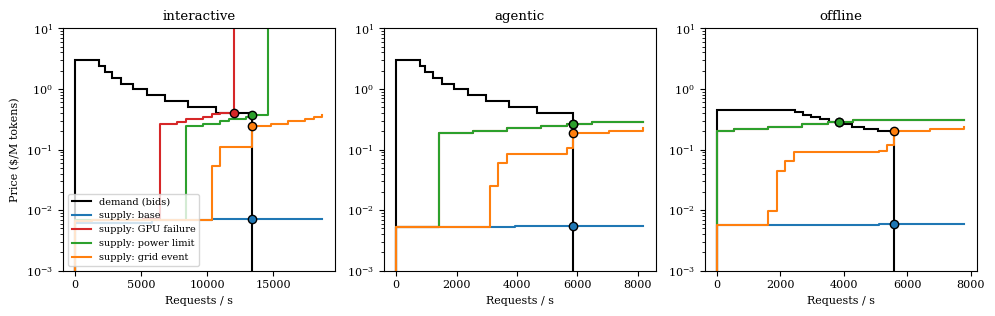

In [ ]:
# %% 8. Figure 1: demand bids, residual supply and market clearing --------------------------
r, t = 1, TPK
CLEAR = {name: clear_market(**kw, hours=[t]) for name, kw in EVENTS.items()}
SUPPLY = {}

for name, kw in EVENTS.items():
    for k in range(K):
        served = CLEAR[name]['served'][k, r, 0]
        Q = np.unique(np.concatenate([np.linspace(1, 1.4 * DEM[r, k, t], 30), [max(served, 1.0)]]))
        q_ok, p_ok = [], []
        for q in Q:
            res = clear_market(**kw, hours=[t], fix=(k, r, q))
            if res is None:
                break                                            # beyond what the fleet can serve
            q_ok.append(q)
            p_ok.append(res['lam'][k, r, 0] / (N_IN[k] + N_OUT[k]) * 1e6)

        if len(q_ok) < len(Q):                                   # capacity reached: find it by bisection
            lo, hi = (q_ok[-1] if q_ok else 0.0), q
            p_lo = p_ok[-1] if p_ok else np.nan
            for _ in range(8):
                mid = (lo + hi) / 2
                res = clear_market(**kw, hours=[t], fix=(k, r, mid))
                if res is None:
                    hi = mid
                else:
                    lo, p_lo = mid, res['lam'][k, r, 0] / (N_IN[k] + N_OUT[k]) * 1e6
            q_ok += [lo, lo]; p_ok += [p_lo, 10]                 # vertical at capacity

        # at zero quantity, supply is vertical up to the cost of the first unit
        SUPPLY[name, k] = (np.array([0, 0] + q_ok), np.array([1e-3, p_ok[0]] + p_ok))

fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
for k, c in enumerate(CLASSES):
    q = SEG_SHARE[k] * DEM[r, k, t]
    order = np.argsort(-PRICE[k]); order = order[q[order] > 0]
    edges = np.concatenate([[0], np.cumsum(q[order])])
    ax[k].stairs(PRICE[k, order], edges, baseline=1e-3, color='k', lw=1.5, label='demand (bids)')
    for name in EVENTS:
        Q, P = SUPPLY[name, k]
        ax[k].plot(Q, P, drawstyle='steps-post', c=COLOR[name], label=f'supply: {name}')
        price = CLEAR[name]['lam'][k, r, 0] / (N_IN[k] + N_OUT[k]) * 1e6
        ax[k].plot(CLEAR[name]['served'][k, r, 0], price, 'o', c=COLOR[name], mec='k', ms=6, zorder=5)
    ax[k].set(yscale='log', ylim=(1e-3, 10), xlabel='Requests / s', title=c)
ax[0].set_ylabel('Price ($/M tokens)')
ax[0].legend(fontsize=7, loc='lower left')
plt.tight_layout(); plt.savefig('fig_clearing.pdf', bbox_inches='tight'); plt.show()

/tmp/ipykernel_3244/2929395445.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)


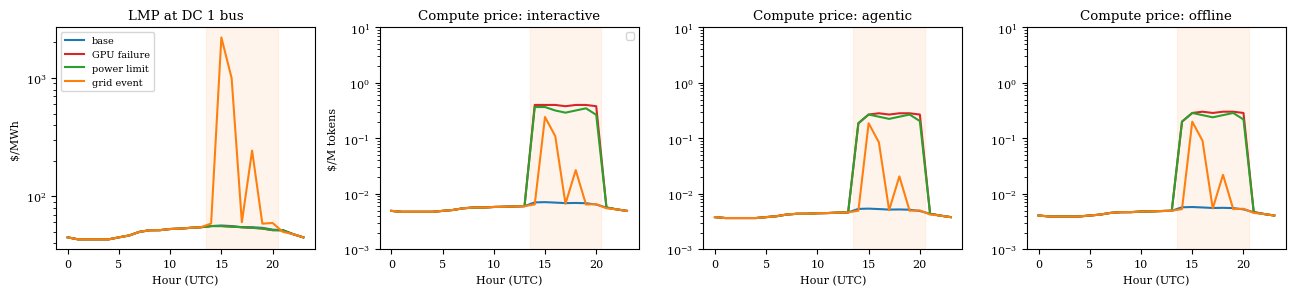

In [ ]:
# %% 9. Figure 2: electricity and compute prices over the day, region 1 ----------------------
hours = np.arange(24)
fig, ax = plt.subplots(1, 4, figsize=(13, 3))
for a in ax:
    a.axvspan(EVENT[0] - 0.5, EVENT[-1] + 0.5, color='C1', alpha=0.08)    # event window
for name in EVENTS:
    ax[0].plot(hours, RES[name]['nu'][:, SBUS[1]], c=COLOR[name], label=name)
ax[0].set(yscale='log', xlabel='Hour (UTC)', ylabel='$/MWh', title='LMP at DC 1 bus')
for k, c in enumerate(CLASSES):
    # ax[k + 1].axhspan(P_LOW[k], P_HIGH[k], color='gray', alpha=0.15, label='range of bids')
    for name in EVENTS:
        ax[k + 1].plot(hours, RES[name]['lam'][k, 1] / (N_IN[k] + N_OUT[k]) * 1e6, c=COLOR[name])
    ax[k + 1].set(yscale='log', ylim=(1e-3, 10), xlabel='Hour (UTC)', title=f'Compute price: {c}')
ax[1].set_ylabel('$/M tokens')
ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig('fig_price_day.pdf', bbox_inches='tight'); plt.show()

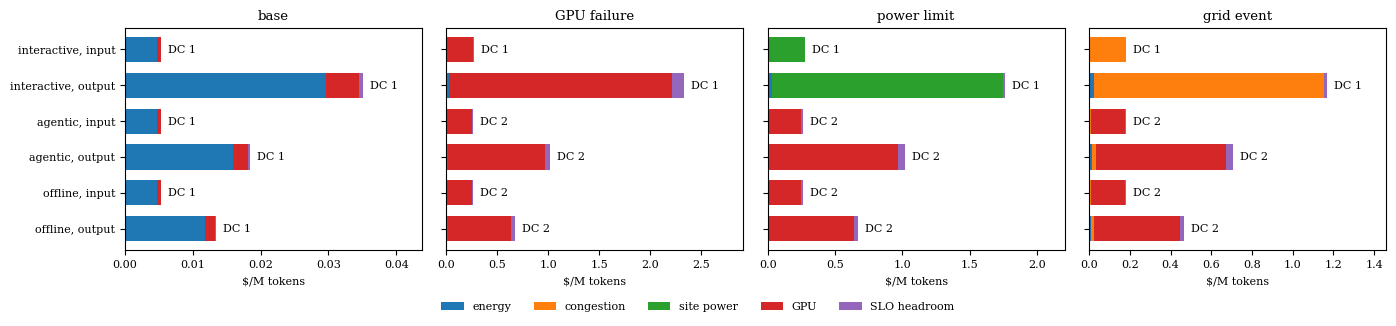

In [ ]:
# %% 10. Figure 3: what the price is made of, per event ------------------------------------
COLORS = {'energy': 'C0', 'congestion': 'C1', 'site power': 'C2', 'GPU': 'C3', 'SLO headroom': 'C4'}
fig, ax = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for j, name in enumerate(EVENTS):
    tab = DECOMP[name][DECOMP[name].region == 1].copy()
    tab.index = tab.cls + ', ' + tab.part
    tab[COMPS].fillna(0).plot.barh(stacked=True, ax=ax[j], width=0.7, legend=False,
                                   color=[COLORS[x] for x in COMPS])
    for y, (total, site) in enumerate(zip(tab[COMPS].sum(axis=1), tab.site)):
        ax[j].text(total, y, '  curtailed' if site < 0 else f'  DC {site}', va='center', fontsize=8)
    ax[j].margins(x=0.25)
    ax[j].set(title=name, xlabel='$/M tokens')
ax[0].invert_yaxis()
fig.legend(*ax[0].get_legend_handles_labels(), loc='lower center', ncol=5,
           frameon=False, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.savefig('fig_decomposition.pdf', bbox_inches='tight'); plt.show()

/usr/local/lib/python3.13/dist-packages/cvxpy/reductions/solvers/solving_chain_utils.py:30: UserWarning: The problem includes expressions that don't support CPP backend. Defaulting to the SCIPY backend for canonicalization.
  warnings.warn(UserWarning(


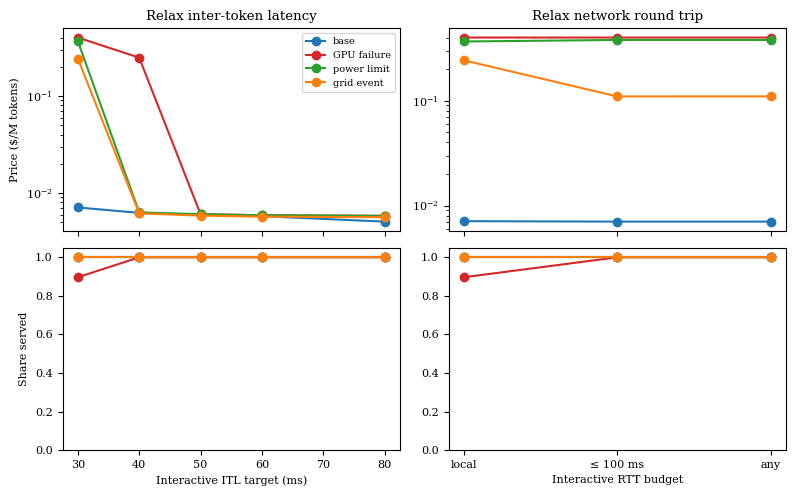

In [ ]:
# %% 11. Figure 4: SLO sweep for interactive, region 1, peak hour ----------------------------
ITL_GRID = [30, 40, 50, 60, 80]                         # ms, interactive ITL target
RTT_GRID = [0.05, 0.10, np.inf]                         # s: local site only / neighbours / anywhere
RTT_LABELS = ['local', '≤ 100 ms', 'any']
k, r = 0, 1                                             # interactive, region 1

SWEEP = []
for name, kw in EVENTS.items():
    for L in ITL_GRID:
        res = clear_market(**kw, l_itl={**L_ITL, 'interactive': L}, hours=[TPK])
        SWEEP.append(dict(event=name, knob='ITL', x=L,
                          price=res['lam'][k, r, 0] / (N_IN[k] + N_OUT[k]) * 1e6,
                          served=res['served'][k, r, 0] / DEM[r, k, TPK]))
    for j, Rb in enumerate(RTT_GRID):
        res = clear_market(**kw, rtt_max={**RTT_MAX, 'interactive': Rb}, hours=[TPK])
        SWEEP.append(dict(event=name, knob='RTT', x=j,
                          price=res['lam'][k, r, 0] / (N_IN[k] + N_OUT[k]) * 1e6,
                          served=res['served'][k, r, 0] / DEM[r, k, TPK]))
SWEEP = pd.DataFrame(SWEEP)

fig, ax = plt.subplots(2, 2, figsize=(8, 5), sharex='col')
for name in EVENTS:
    for col, knob in enumerate(['ITL', 'RTT']):
        sw = SWEEP[(SWEEP.event == name) & (SWEEP.knob == knob)]
        ax[0, col].plot(sw.x, sw.price, 'o-', c=COLOR[name], label=name)
        ax[1, col].plot(sw.x, sw.served, 'o-', c=COLOR[name])
ax[0, 0].set(yscale='log', ylabel='Price ($/M tokens)', title='Relax inter-token latency')
ax[0, 1].set(yscale='log', title='Relax network round trip')
ax[1, 0].set(xlabel='Interactive ITL target (ms)', ylabel='Share served', ylim=(0, 1.05))
ax[1, 1].set(xlabel='Interactive RTT budget', ylim=(0, 1.05))
ax[1, 1].set_xticks(range(len(RTT_GRID)), RTT_LABELS)
ax[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.savefig('fig_slo_sweep.pdf', bbox_inches='tight'); plt.show()

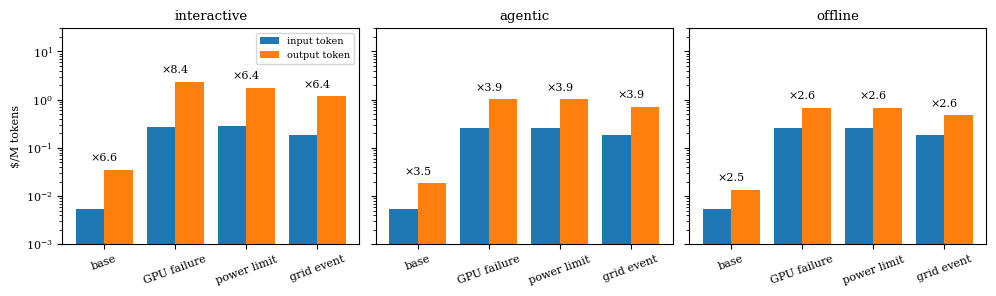

In [ ]:
# %% 12. Figure 5: price per input vs. output token, region 1, peak hour ----------------------
names = list(EVENTS); x = np.arange(len(names))
fig, ax = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for k, c in enumerate(CLASSES):
    p_in, p_out = [], []
    for name in names:
        tab = DECOMP[name][(DECOMP[name].region == 1) & (DECOMP[name].cls == c)].set_index('part')
        p_in.append(tab.loc['input', COMPS].sum(min_count=1))
        p_out.append(tab.loc['output', COMPS].sum(min_count=1))
    p_in, p_out = np.array(p_in, dtype=float), np.array(p_out, dtype=float)
    ax[k].bar(x - 0.2, p_in, 0.4, label='input token')
    ax[k].bar(x + 0.2, p_out, 0.4, label='output token')
    for j in range(len(names)):
        label = 'curtailed' if np.isnan(p_in[j]) else f'×{p_out[j] / p_in[j]:.1f}'
        ax[k].text(x[j], np.nanmax([p_out[j], 1e-3]) * 1.5, label, ha='center', fontsize=8)
    ax[k].set_xticks(x, names, rotation=20)
    ax[k].set(yscale='log', ylim=(1e-3, 30), title=c)
ax[0].set_ylabel('$/M tokens')
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig('fig_input_output.pdf', bbox_inches='tight'); plt.show()

In [ ]:
# # %% 8. Figure 1: demand bids, supply curve and market clearing -----------------------------
# r, t = 1, TPK
# SUPPLY, CLEAR = {}, {}
# for name, kw in SCENARIOS.items():
#     CLEAR[name] = clear_market(**kw, hours=[t])
#     for k in range(K):
#         Q, P = np.linspace(0, 1.4 * DEM[r, k, t], 20), []
#         for q in Q:
#             res = clear_market(**kw, hours=[t], fix=(k, r, q))
#             if res is None:
#                 break                                            # beyond what the fleet can serve
#             P.append(res['lam'][k, r, 0] / (N_IN[k] + N_OUT[k]) * 1e6)
#         Q, P = Q[:len(P)], np.array(P)
#         if len(P) < 20:                                          # hit capacity: supply turns vertical
#             Q, P = np.append(Q, Q[-1]), np.append(P, 10)
#         SUPPLY[name, k] = (Q, P)

# fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
# for k, c in enumerate(CLASSES):
#     q = SEG_SHARE[k] * DEM[r, k, t]
#     order = np.argsort(-PRICE[k]); order = order[q[order] > 0]
#     edges = np.concatenate([[0], np.cumsum(q[order])])
#     ax[k].stairs(PRICE[k, order], edges, baseline=1e-3, color='k', lw=1.5, label='demand (bids)')
#     for name in SCENARIOS:
#         Q, P = SUPPLY[name, k]
#         ax[k].plot(Q, P, c=COLOR[name], label=f'supply: {name}')
#         price = CLEAR[name]['lam'][k, r, 0] / (N_IN[k] + N_OUT[k]) * 1e6
#         ax[k].plot(CLEAR[name]['served'][k, r, 0], price, 'o', c=COLOR[name], mec='k', ms=6)
#     ax[k].set(yscale='log', ylim=(1e-3, 10), xlabel='Requests / s', title=c)
# ax[0].set_ylabel('Price ($/M tokens)')
# ax[0].legend(fontsize=7, loc='lower left')
# plt.tight_layout(); plt.savefig('fig_clearing.pdf', bbox_inches='tight'); plt.show()

In [ ]:
# # %% 9. Figure 2: electricity and compute prices over the day, region 1 ---------------------
# SHOW  = ['base', 'DC 1 power: 10 MW', 'grid event at bus 8']
# hours = np.arange(24)

# fig, ax = plt.subplots(1, 4, figsize=(12, 3))
# for name in SHOW:
#     ax[0].plot(hours, RES[name]['nu'][:, SBUS[1]], c=COLOR[name], label=name)
# ax[0].set(yscale='log', xlabel='Hour (UTC)', ylabel='$/MWh', title='LMP at DC 1 bus')
# for k, c in enumerate(CLASSES):
#     ax[k + 1].axhspan(P_LOW[k], P_HIGH[k], color='gray', alpha=0.15, label='range of bids')
#     for name in SHOW:
#         ax[k + 1].plot(hours, RES[name]['lam'][k, 1] / (N_IN[k] + N_OUT[k]) * 1e6, c=COLOR[name])
#     ax[k + 1].set(yscale='log', ylim=(1e-3, 10), xlabel='Hour (UTC)', title=f'Compute price: {c}')
# ax[1].set_ylabel('$/M tokens')
# ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
# plt.tight_layout(); plt.savefig('fig_price_day.pdf', bbox_inches='tight'); plt.show()

In [ ]:
# # %% 10. Figure 3: what the price is made of (region 1, peak hour) --------------------------
# SHOW   = ['base', 'DC 1 power: 10 MW', 'grid event at bus 8']
# COLORS = {'energy': 'C0', 'congestion': 'C1', 'site power': 'C2', 'GPU': 'C3', 'SLO headroom': 'C4'}

# fig, ax = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
# for j, name in enumerate(SHOW):
#     tab = DECOMP[name][DECOMP[name].region == 1].copy()
#     tab.index = tab.cls + ', ' + tab.part
#     tab[COMPS].plot.barh(stacked=True, ax=ax[j], width=0.7, legend=False,
#                          color=[COLORS[x] for x in COMPS])
#     for y, (total, site) in enumerate(zip(tab[COMPS].sum(axis=1), tab.site)):
#         ax[j].text(total, y, f'  DC {site}', va='center', fontsize=8)
#     ax[j].set(title=name, xlabel='$/M tokens')
# ax[0].invert_yaxis()
# fig.legend(*ax[0].get_legend_handles_labels(), loc='lower center', ncol=5,
#            frameon=False, bbox_to_anchor=(0.5, -0.08))
# plt.tight_layout(); plt.savefig('fig_decomposition.pdf', bbox_inches='tight'); plt.show()

In [ ]:
# # %% 8. Figure 1: prices across the day (base case) ----------------------------------
# base, hours = RES[1.0], np.arange(T)
# EFF = base['lam'] / (N_IN + N_OUT)[:, None, None] * 1e6         # $/M tokens [class, region, hour]

# fig, ax = plt.subplots(1, 3, figsize=(7.16, 2.3))
# for s in range(S):
#     ax[0].plot(hours, base['nu'][:, SBUS[s]], label=f'DC {s} (bus {SITE_BUS[s]})')
# ax[0].set(xlabel='Hour (UTC)', ylabel='LMP ($/MWh)', title='(a) Electricity at sites')
# for j, r in enumerate([0, 1]):
#     for k, c in enumerate(CLASSES):
#         ax[j + 1].plot(hours, EFF[k, r], c=f'C{k}', label=c)
#     for p in [0.40, 0.90, 3.00]:
#         ax[j + 1].axhline(p, c='gray', ls=':', lw=0.7)          # bid prices
#     ax[j + 1].set(yscale='log', xlabel='Hour (UTC)', ylabel='Compute price ($/M tokens)',
#                   title=f'({"bc"[j]}) Region {r}')
# ax[0].legend(fontsize=6); ax[1].legend(fontsize=6)
# plt.tight_layout(); plt.savefig('fig_price_day.pdf', bbox_inches='tight'); plt.show()

In [ ]:
# # %% 9. Figure 2: decomposition of the price, input vs. output tokens ----------------
# NAMES = {'interactive': 'Interactive', 'agentic': 'Agentic', 'offline': 'Offline'}
# fig, ax = plt.subplots(1, 2, figsize=(7.16, 2.5), sharey=True)
# for j, frac in enumerate([1.0, 0.4]):
#     tab = DECOMP[frac].query('region == 1').set_index(['cls', 'part'])[COMPS]
#     tab.index = [f'{NAMES[c]}\n{p}' for c, p in tab.index]
#     tab.plot.bar(stacked=True, ax=ax[j], rot=0, width=0.7, legend=(j == 0))
#     ax[j].set(title=f'({"ab"[j]}) Site 1 power at {frac:.0%}, hour {TPK}', ylabel='$/M tokens')
#     ax[j].axhline(0, c='k', lw=0.5)
# ax[0].legend(fontsize=6)
# plt.tight_layout(); plt.savefig('fig_decomposition.pdf', bbox_inches='tight'); plt.show()

In [ ]:
# # %% 10. Figure 3: sensitivity to the power available at site 1 ----------------------
# cap_MW    = np.array(SITE1_POWER) * SITE_MW[1]
# price_r1  = np.array([RES[f]['lam'][:, 1, TPK] / (N_IN + N_OUT) * 1e6 for f in SITE1_POWER])   # [scenario, class]
# served_r1 = np.array([RES[f]['served'][:, 1, TPK] / DEM[1, :, TPK] for f in SITE1_POWER])
# site_MW   = np.array([RES[f]['P_dc'][:, TPK] for f in SITE1_POWER])                          # [scenario, site]

# fig, ax = plt.subplots(1, 3, figsize=(7.16, 2.3))
# for k, c in enumerate(CLASSES):
#     ax[0].plot(cap_MW, price_r1[:, k], 'o-', c=f'C{k}', label=c)
#     ax[1].plot(cap_MW, served_r1[:, k], 'o-', c=f'C{k}', label=c)
# for s in range(S):
#     ax[2].plot(cap_MW, site_MW[:, s], 's-', label=f'DC {s}')
# ax[0].set(yscale='log', ylabel='Price, region 1 ($/M tokens)', title='(a) Compute price')
# ax[1].set(ylabel='Share of demand served', ylim=(0, 1.05), title='(b) Served, region 1')
# ax[2].set(ylabel='Site load (MW)', title='(c) Load moves between sites')
# for a in ax: a.set_xlabel('Site 1 power limit (MW)'); a.invert_xaxis()
# ax[0].legend(fontsize=6); ax[2].legend(fontsize=6)
# plt.tight_layout(); plt.savefig('fig_sensitivity.pdf', bbox_inches='tight'); plt.show()

In [ ]:
# # %% 11. Figure 4: site load over the day, base vs. power-limited site 1 ---------------
# fig, ax = plt.subplots(1, 2, figsize=(7.16, 2.3), sharey=True)
# for j, frac in enumerate([1.0, 0.4]):
#     for s in range(S):
#         ax[j].plot(hours, RES[frac]['P_dc'][s], c=f'C{s}', label=f'DC {s}')
#     ax[j].axhline(RES[frac]['PCAP'][1], c='C1', ls='--', lw=0.8, label='DC 1 limit')
#     ax[j].set(xlabel='Hour (UTC)', ylabel='Site load (MW)', title=f'({"ab"[j]}) Site 1 power at {frac:.0%}')
# ax[0].legend(fontsize=6)
# plt.tight_layout(); plt.savefig('fig_site_load.pdf', bbox_inches='tight'); plt.show()

In [ ]:
# # %% 8. Figure 1: bids and market clearing, region 1 at the peak hour ------------------
# # Black staircase = demand bids. Dots = cleared quantity and price for each site-1 power limit.
# r, t = 1, TPK
# SCEN    = [1.0, 0.6, 0.4, 0.3]                   # site 1 power limit, share of 25 MW
# MARKERS = ['o', 's', '^', 'D']

# fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
# for k, c in enumerate(CLASSES):
#     q = SEG_SHARE[k] * DEM[r, k, t]              # req/s in each bid segment
#     order = np.argsort(-PRICE[k])                # highest value first
#     order = order[q[order] > 0]                  # drop empty segments
#     edges = np.concatenate([[0], np.cumsum(q[order])])
#     ax[k].stairs(PRICE[k, order], edges, color='k', lw=1.5, baseline=None, label='bids')

#     for frac, mk in zip(SCEN, MARKERS):
#         served = RES[frac]['served'][k, r, t]
#         price  = RES[frac]['lam'][k, r, t] / (N_IN[k] + N_OUT[k]) * 1e6
#         ax[k].plot(served, price, mk, ms=7, label=f'DC 1 at {frac * SITE_MW[1]:.0f} MW')

#     ax[k].set(yscale='log', ylim=(1e-3, 10), xlim=(0, 1.1 * edges[-1]),
#               xlabel='Requests / s', title=c)
# ax[0].set_ylabel('Price ($/M tokens)')
# ax[0].legend(fontsize=8)
# plt.tight_layout(); plt.savefig('fig_clearing.pdf', bbox_inches='tight'); plt.show()

In [ ]:
# # %% 9. Figure 2: compute price across the day, region 1, for several power limits ------
# SCEN_DAY = [1.0, 0.6, 0.4]
# hours = np.arange(T)

# fig, ax = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
# for k, c in enumerate(CLASSES):
#     for frac in SCEN_DAY:
#         price = RES[frac]['lam'][k, 1] / (N_IN[k] + N_OUT[k]) * 1e6      # $/M tokens over the day
#         ax[k].plot(hours, price, label=f'DC 1 at {frac * SITE_MW[1]:.0f} MW')
#     for p in np.unique(PRICE[k]):
#         ax[k].axhline(p, color='gray', ls=':', lw=0.8)                  # bid prices
#     ax[k].set(yscale='log', xlabel='Hour (UTC)', title=c)
# ax[0].set_ylabel('Price, region 1 ($/M tokens)')
# ax[0].legend(fontsize=8)
# plt.tight_layout(); plt.savefig('fig_price_day.pdf', bbox_inches='tight'); plt.show()

In [ ]:
# # %% 10. Figure 3: what the price is made of, input vs. output tokens (DC 1 at 40%) -----
# frac = 0.4
# tab_all = DECOMP[frac]
# COLORS  = {'energy': 'C0', 'congestion': 'C1', 'site power': 'C2', 'GPU': 'C3'}
# SHOWN   = [c for c in COMPS if tab_all[c].abs().max() > 1e-6]      # skip components that are always zero

# fig, ax = plt.subplots(1, 3, figsize=(10, 3), sharex=True, sharey=True)
# for r in range(R):
#     tab = tab_all[tab_all.region == r].copy()
#     tab.index = tab.cls + ', ' + tab.part
#     tab[SHOWN].plot.barh(stacked=True, ax=ax[r], width=0.7, legend=(r == 0),
#                          color=[COLORS[c] for c in SHOWN])
#     for y, (total, site) in enumerate(zip(tab[SHOWN].sum(axis=1), tab.site)):
#         ax[r].text(total + 0.03, y, f'DC {site}', va='center', fontsize=8)
#     ax[r].set(title=f'Region {r}', xlabel='$/M tokens')
# ax[0].invert_yaxis()                             # interactive on top
# ax[0].legend(fontsize=8, loc='lower right')
# plt.tight_layout(); plt.savefig('fig_decomposition.pdf', bbox_inches='tight'); plt.show()